In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings

warnings.simplefilter("ignore")

In [3]:
df = pd.read_csv("../artifacts/raw/train.csv")

df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN17542,2,0,2,1,Meal Plan 1,0,Room_Type 4,68,2018,3,19,Online,0,0,0,105.30,2,Not_Canceled
1,INN04375,2,2,2,5,Meal Plan 1,0,Room_Type 6,196,2018,7,24,Online,0,0,0,158.95,0,Canceled
2,INN35188,2,0,1,3,Not Selected,0,Room_Type 1,52,2018,12,1,Online,0,0,0,74.80,2,Not_Canceled
3,INN16450,2,0,2,0,Meal Plan 1,0,Room_Type 4,3,2018,2,21,Online,0,0,0,105.00,0,Not_Canceled
4,INN24505,2,0,1,4,Meal Plan 1,0,Room_Type 4,62,2018,4,11,Online,0,0,0,112.20,0,Not_Canceled


In [4]:
df.isna().sum()

Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

In [5]:
df.isnull().sum()

Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

In [6]:
df.shape

(29020, 19)

In [7]:
numerical_columns = df.select_dtypes(include=["number"]).columns.to_list()

numerical_columns

['no_of_adults',
 'no_of_children',
 'no_of_weekend_nights',
 'no_of_week_nights',
 'required_car_parking_space',
 'lead_time',
 'arrival_year',
 'arrival_month',
 'arrival_date',
 'repeated_guest',
 'no_of_previous_cancellations',
 'no_of_previous_bookings_not_canceled',
 'avg_price_per_room',
 'no_of_special_requests']

In [8]:
categorical_columns = df.select_dtypes(exclude=["number"]).columns.to_list()
categorical_columns

['Booking_ID',
 'type_of_meal_plan',
 'room_type_reserved',
 'market_segment_type',
 'booking_status']

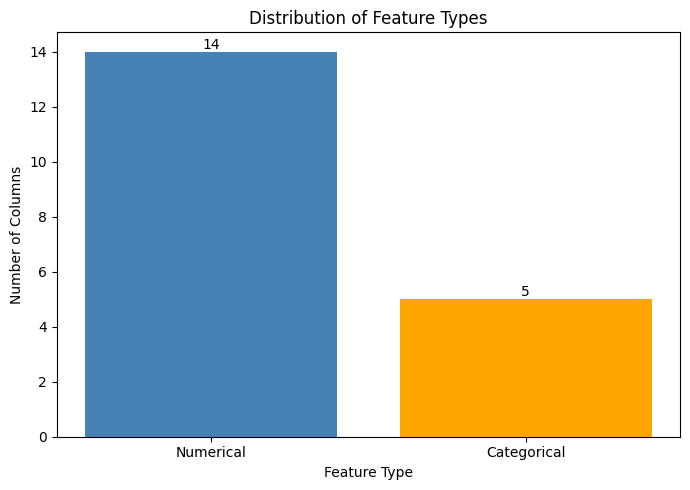

In [9]:
columns_counts = {
    "Numerical": len(numerical_columns),
    "Categorical": len(categorical_columns),
}


plt.figure(figsize=(7, 5))

bars = plt.bar(
    columns_counts.keys(), columns_counts.values(), color=["steelblue", "orange"]
)

plt.bar_label(bars)

plt.title("Distribution of Feature Types")
plt.xlabel("Feature Type")
plt.ylabel("Number of Columns")

plt.tight_layout()
plt.show()

In [10]:
df.drop(columns=["Booking_ID"], axis=1, inplace=True)

In [11]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,2,1,Meal Plan 1,0,Room_Type 4,68,2018,3,19,Online,0,0,0,105.30,2,Not_Canceled
1,2,2,2,5,Meal Plan 1,0,Room_Type 6,196,2018,7,24,Online,0,0,0,158.95,0,Canceled
2,2,0,1,3,Not Selected,0,Room_Type 1,52,2018,12,1,Online,0,0,0,74.80,2,Not_Canceled
3,2,0,2,0,Meal Plan 1,0,Room_Type 4,3,2018,2,21,Online,0,0,0,105.00,0,Not_Canceled
4,2,0,1,4,Meal Plan 1,0,Room_Type 4,62,2018,4,11,Online,0,0,0,112.20,0,Not_Canceled


In [12]:
df.duplicated().sum()

np.int64(7695)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
for column in df.columns.to_list():
    print(f"========================= {column} =============================")
    print(df[column].value_counts())
    print(f"================================================================")
    print("\n\n")

========================= no_of_adults =============================
no_of_adults
2    15440
1     3994
3     1773
0      105
4       13
Name: count, dtype: int64



========================= no_of_children =============================
no_of_children
0     19270
1      1219
2       817
3        17
10        1
9         1
Name: count, dtype: int64



========================= no_of_weekend_nights =============================
no_of_weekend_nights
0    9080
1    6089
2    5916
4     105
3      99
5      19
6      16
7       1
Name: count, dtype: int64



========================= no_of_week_nights =============================
no_of_week_nights
2     5902
1     5793
3     4632
4     1962
0     1518
5     1143
6      141
7       79
8       48
10      39
9       25
11      15
12       8
14       7
15       6
17       3
13       3
16       1
Name: count, dtype: int64



========================= type_of_meal_plan =============================
type_of_meal_plan
Meal Plan 1     16759
Not Sel

## **UNIVARIATE ANALSIS**

In [16]:
data = df.copy()

In [17]:
def num_plot_dist(df, num_features):
    fig, axes = plt.subplots(len(num_features), 2, figsize=(15, len(num_features) * 5))

    if len(num_features) == 1:
        axes = [axes]

    for i, column in enumerate(num_features):
        sns.histplot(data=df, x=column, ax=axes[i][0], kde=True, palette="Blues")
        axes[i][0].set_title(f"Histogram for {column}")

        sns.boxplot(data=df, x=column, ax=axes[i][1], palette="Blues")
        axes[i][1].set_title(f"Box Plot for {column}")

    plt.tight_layout()
    plt.show()

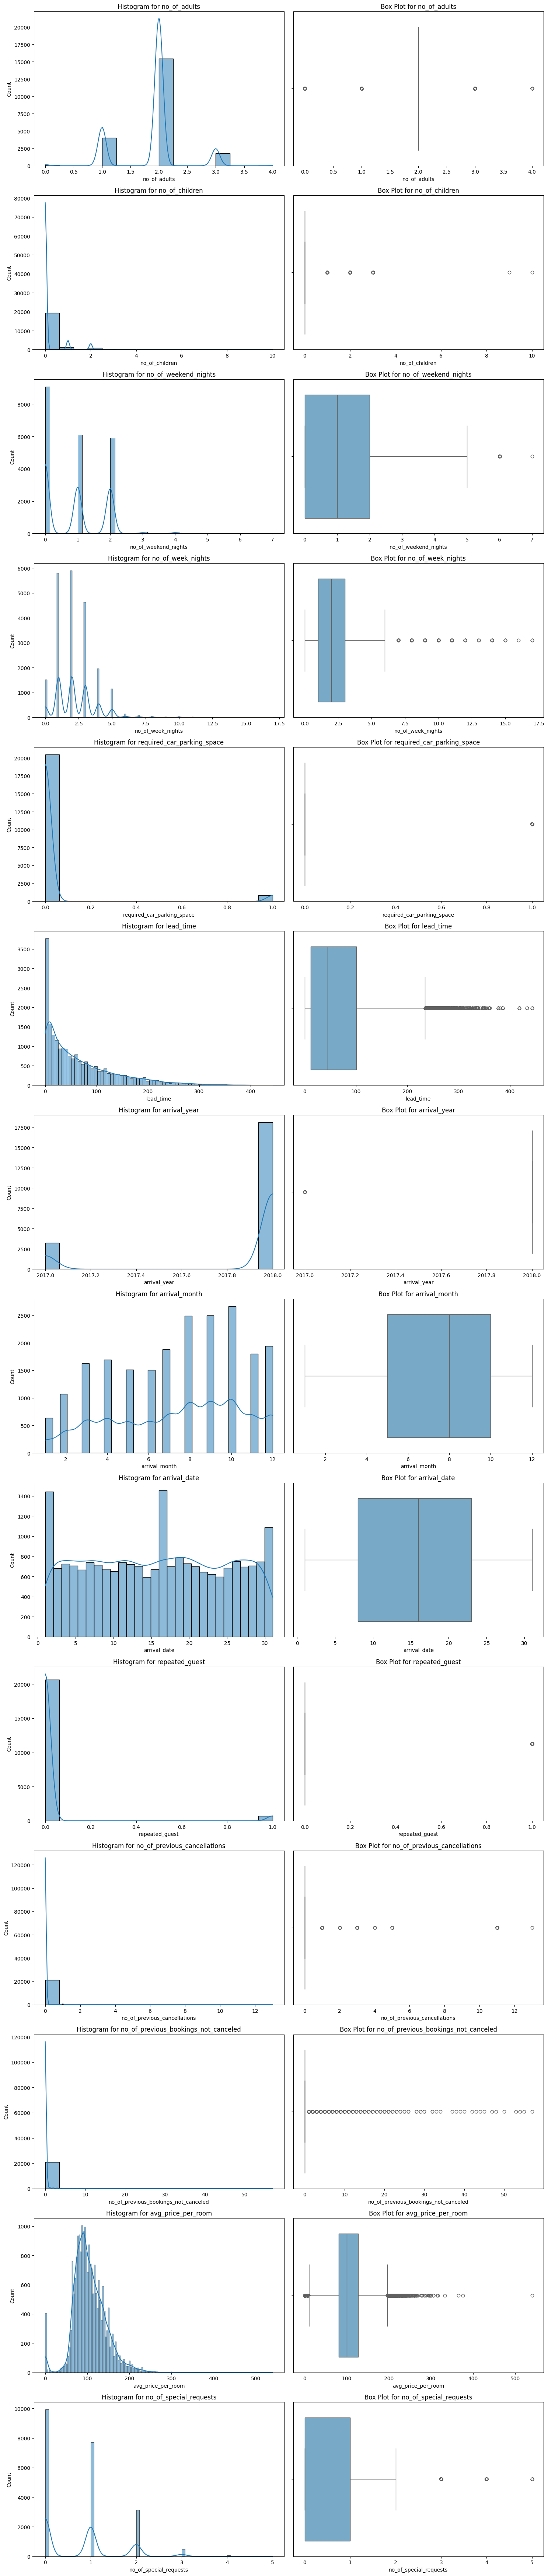

In [18]:
num_plot_dist(data, numerical_columns)

<Figure size 1000x600 with 0 Axes>

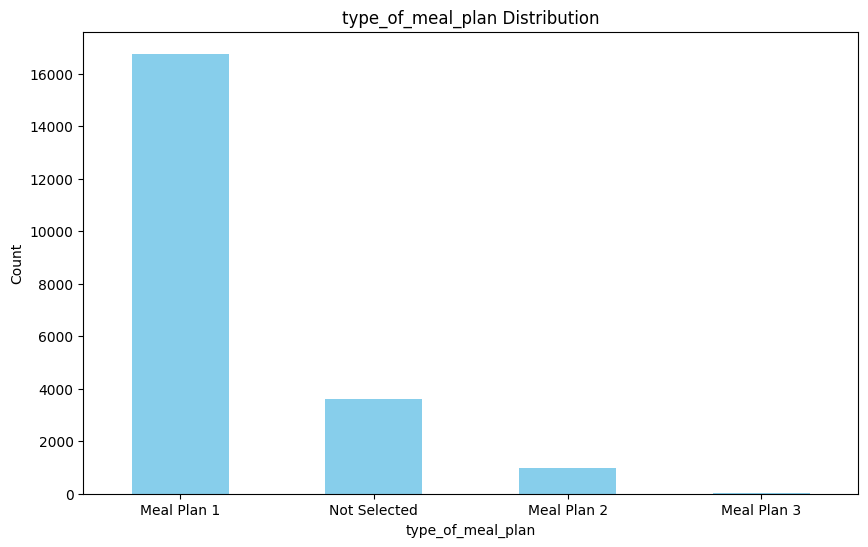

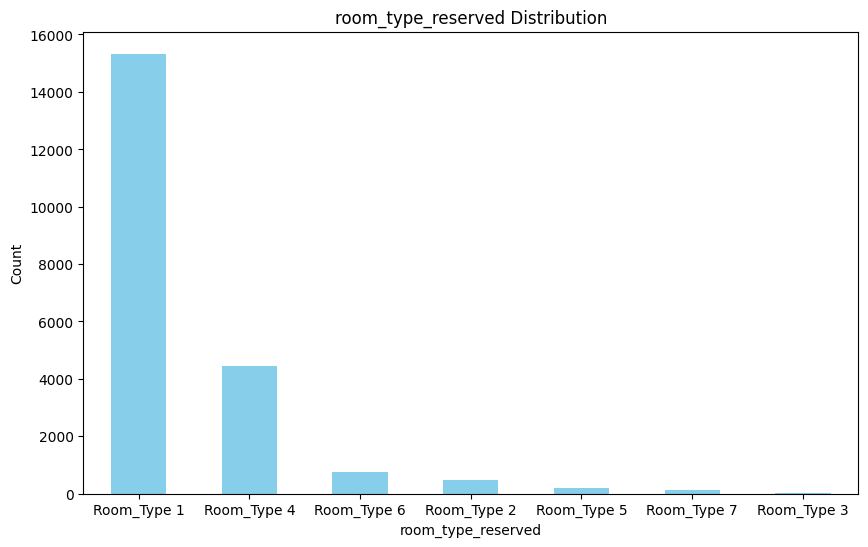

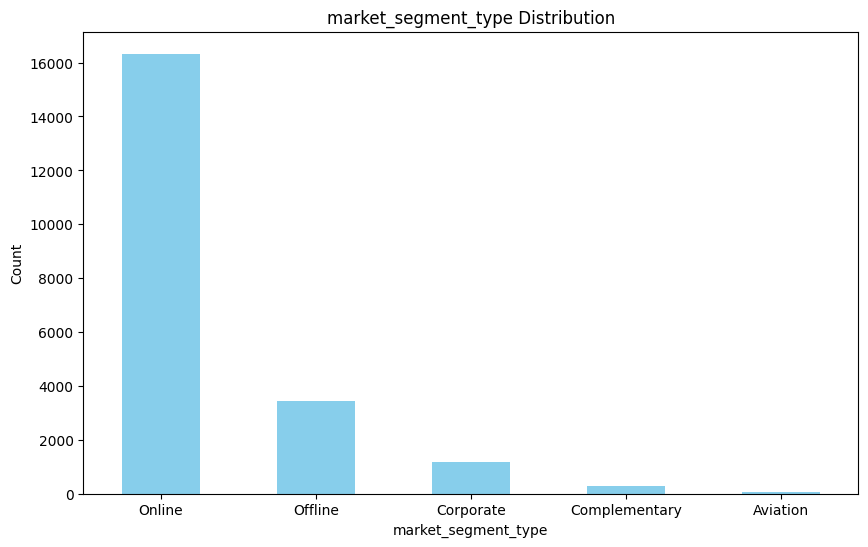

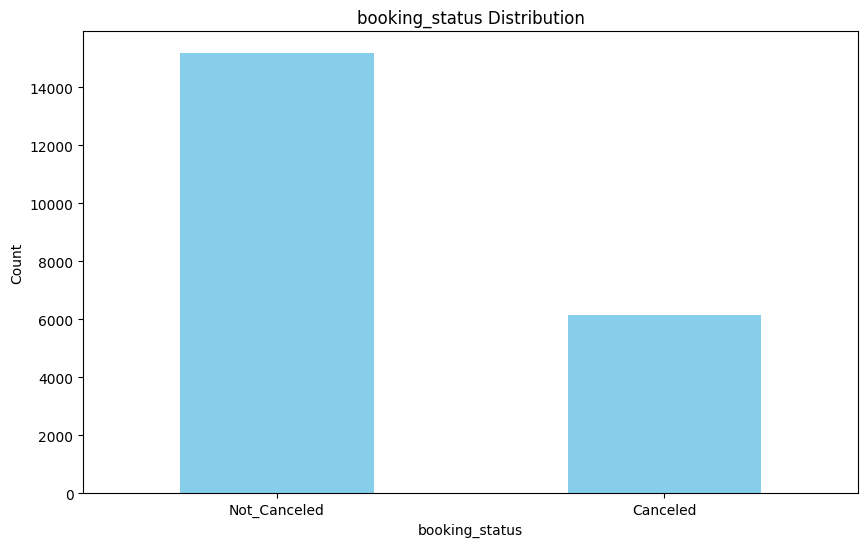

In [19]:
for categorical_feature in categorical_columns:
    plt.figure(figsize=(10, 6))
    if categorical_feature == "Booking_ID":
        continue
    data[categorical_feature].value_counts().plot(kind="bar", color="skyblue")
    plt.title(f"{categorical_feature} Distribution")
    plt.xlabel(categorical_feature)
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.show()

## **BIVARIATE ANALYSIS**

In [20]:
def plot_bivariate_num(df, target, numerical_features):
    num_plots = len(numerical_features)
    num_rows = (num_plots + 1) // 2

    fig, axes = plt.subplots(num_rows, 2, figsize=(15, (num_rows * 5)))

    axes = axes.flatten()

    for i, column in enumerate(numerical_features):
        sns.boxplot(x=target, y=column, ax=axes[i], data=df, palette="Blues")

        axes[i].set_title(f"{column} v/s {target}")

    plt.tight_layout()
    plt.show()

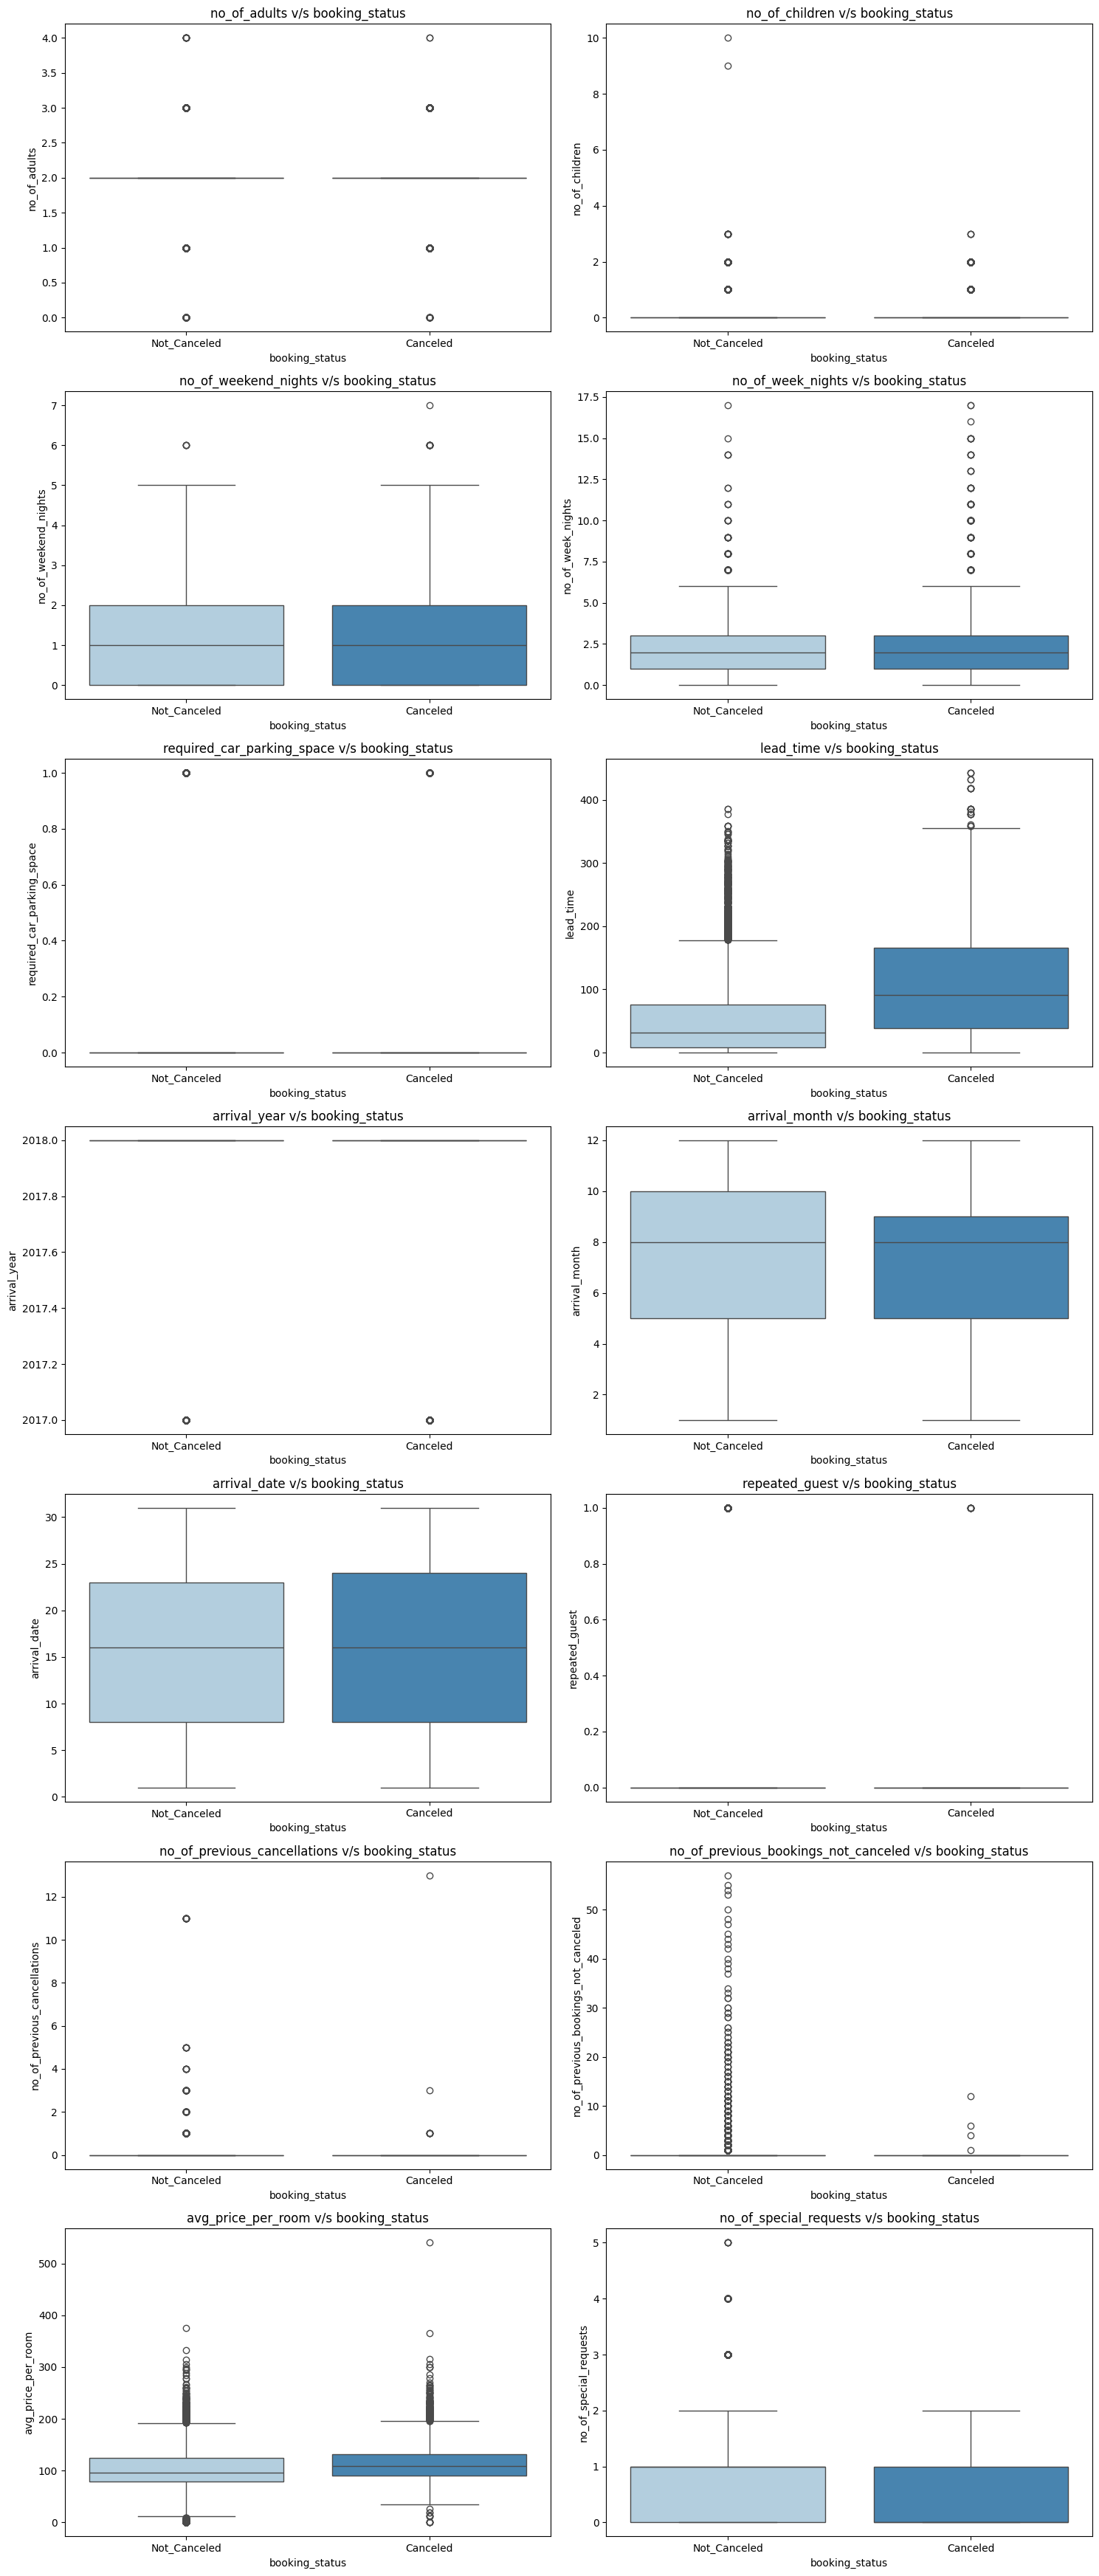

In [21]:
plot_bivariate_num(data, "booking_status", numerical_columns)

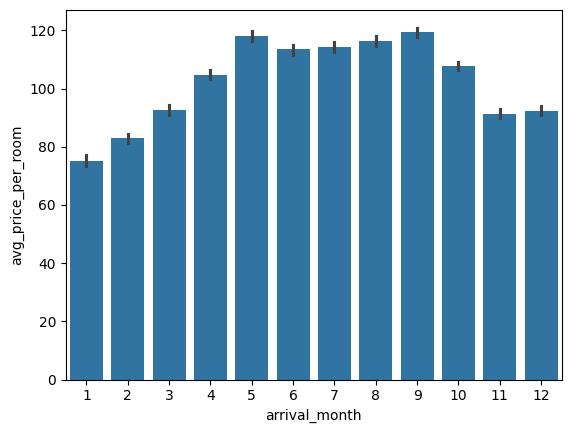

In [22]:
sns.barplot(x="arrival_month", y="avg_price_per_room", data=data)
plt.show()

In [23]:
categorical_columns = data.select_dtypes(include=["object"]).columns.to_list()


def plot_bivariate_cat(df, target, categorical_features):
    num_of_features = len(categorical_features)
    num_of_rows = (num_of_features + 1) // 2

    fig, axes = plt.subplots(num_of_rows, 2, figsize=(15, num_of_rows * 5))

    axes = axes.flatten()

    for i, feature in enumerate(categorical_features):
        # if feature == "Booking_ID":
        #     continue
        sns.countplot(x=feature, hue=target, data=df, palette="Set2", ax=axes[i])

        axes[i].set_title(f"{feature} v/s {target}")
        axes[i].tick_params(axis="x", rotation=90)

    plt.tight_layout()
    plt.show()

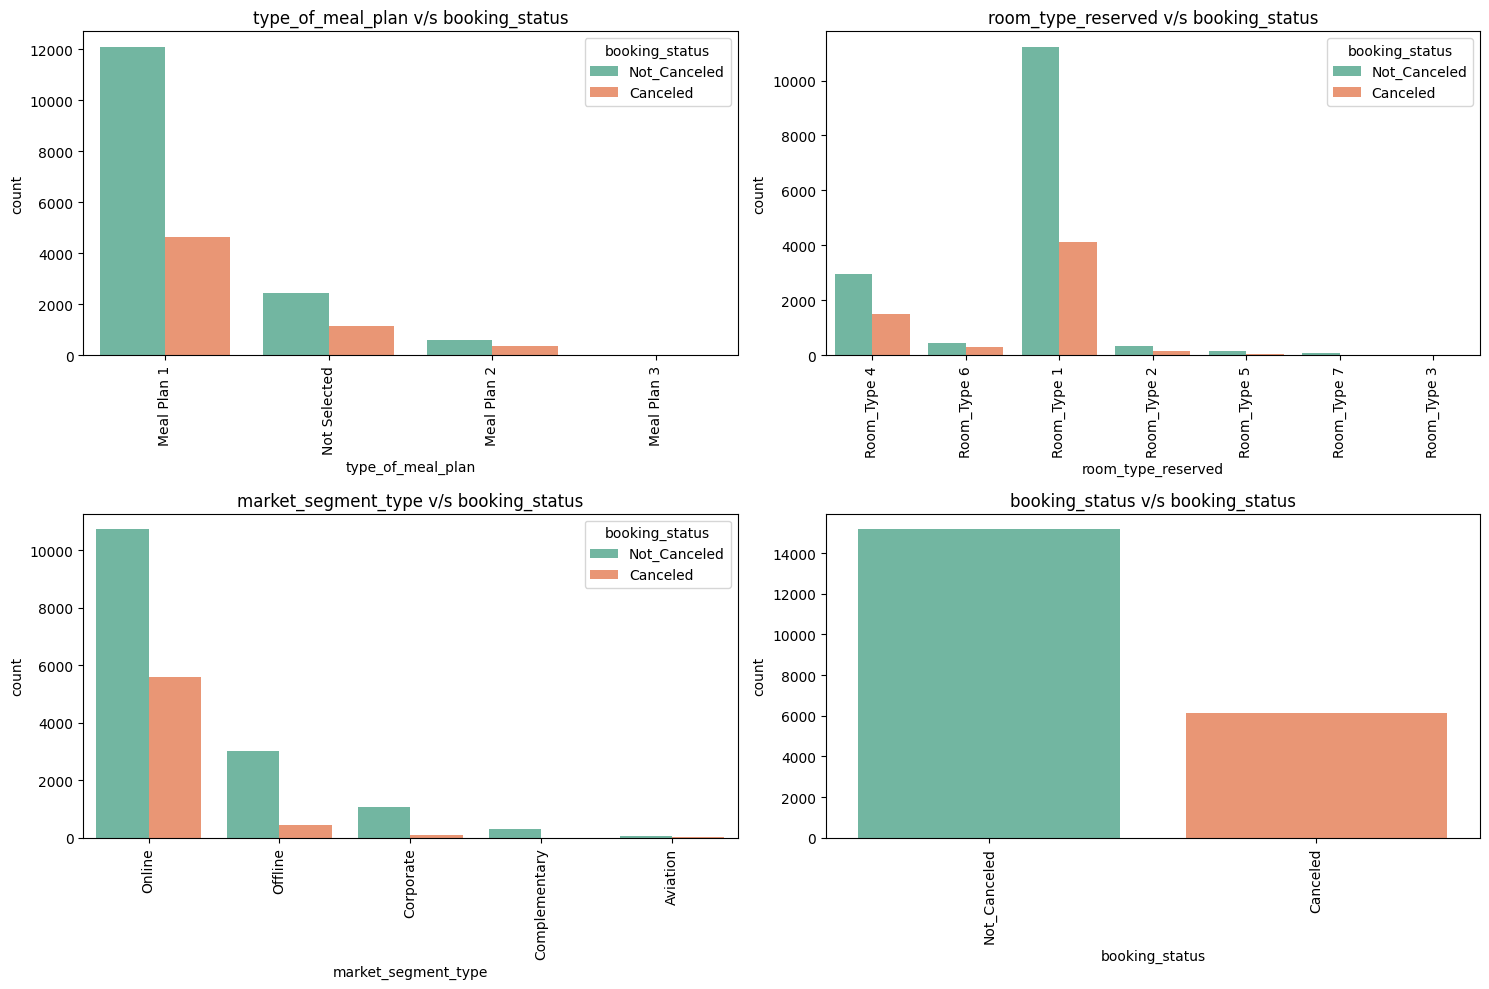

In [24]:
plot_bivariate_cat(data, "booking_status", categorical_columns)

## **Data Processing**

In [25]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,2,1,Meal Plan 1,0,Room_Type 4,68,2018,3,19,Online,0,0,0,105.30,2,Not_Canceled
1,2,2,2,5,Meal Plan 1,0,Room_Type 6,196,2018,7,24,Online,0,0,0,158.95,0,Canceled
2,2,0,1,3,Not Selected,0,Room_Type 1,52,2018,12,1,Online,0,0,0,74.80,2,Not_Canceled
3,2,0,2,0,Meal Plan 1,0,Room_Type 4,3,2018,2,21,Online,0,0,0,105.00,0,Not_Canceled
4,2,0,1,4,Meal Plan 1,0,Room_Type 4,62,2018,4,11,Online,0,0,0,112.20,0,Not_Canceled


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21325 entries, 0 to 29019
Data columns (total 18 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          21325 non-null  int64  
 1   no_of_children                        21325 non-null  int64  
 2   no_of_weekend_nights                  21325 non-null  int64  
 3   no_of_week_nights                     21325 non-null  int64  
 4   type_of_meal_plan                     21325 non-null  object 
 5   required_car_parking_space            21325 non-null  int64  
 6   room_type_reserved                    21325 non-null  object 
 7   lead_time                             21325 non-null  int64  
 8   arrival_year                          21325 non-null  int64  
 9   arrival_month                         21325 non-null  int64  
 10  arrival_date                          21325 non-null  int64  
 11  market_segment_type 

In [27]:
for column in categorical_columns:
    print(df[column].value_counts())
    print("================================")
    print("\n")

type_of_meal_plan
Meal Plan 1     16759
Not Selected     3600
Meal Plan 2       962
Meal Plan 3         4
Name: count, dtype: int64


room_type_reserved
Room_Type 1    15334
Room_Type 4     4438
Room_Type 6      750
Room_Type 2      489
Room_Type 5      193
Room_Type 7      117
Room_Type 3        4
Name: count, dtype: int64


market_segment_type
Online           16335
Offline           3451
Corporate         1169
Complementary      294
Aviation            76
Name: count, dtype: int64


booking_status
Not_Canceled    15171
Canceled         6154
Name: count, dtype: int64




### **Label Encoding**

In [28]:
from sklearn.preprocessing import LabelEncoder

In [29]:
le = LabelEncoder()

mappings = {}

for column in categorical_columns:
    df[column] = le.fit_transform(df[column])

    mappings[column] = {
        label: code for label, code in zip(le.classes_, le.transform(le.classes_))
    }

In [30]:
mappings

{'type_of_meal_plan': {'Meal Plan 1': np.int64(0),
  'Meal Plan 2': np.int64(1),
  'Meal Plan 3': np.int64(2),
  'Not Selected': np.int64(3)},
 'room_type_reserved': {'Room_Type 1': np.int64(0),
  'Room_Type 2': np.int64(1),
  'Room_Type 3': np.int64(2),
  'Room_Type 4': np.int64(3),
  'Room_Type 5': np.int64(4),
  'Room_Type 6': np.int64(5),
  'Room_Type 7': np.int64(6)},
 'market_segment_type': {'Aviation': np.int64(0),
  'Complementary': np.int64(1),
  'Corporate': np.int64(2),
  'Offline': np.int64(3),
  'Online': np.int64(4)},
 'booking_status': {'Canceled': np.int64(0), 'Not_Canceled': np.int64(1)}}

In [31]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,2,1,0,0,3,68,2018,3,19,4,0,0,0,105.30,2,1
1,2,2,2,5,0,0,5,196,2018,7,24,4,0,0,0,158.95,0,0
2,2,0,1,3,3,0,0,52,2018,12,1,4,0,0,0,74.80,2,1
3,2,0,2,0,0,0,3,3,2018,2,21,4,0,0,0,105.00,0,1
4,2,0,1,4,0,0,3,62,2018,4,11,4,0,0,0,112.20,0,1


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21325 entries, 0 to 29019
Data columns (total 18 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          21325 non-null  int64  
 1   no_of_children                        21325 non-null  int64  
 2   no_of_weekend_nights                  21325 non-null  int64  
 3   no_of_week_nights                     21325 non-null  int64  
 4   type_of_meal_plan                     21325 non-null  int64  
 5   required_car_parking_space            21325 non-null  int64  
 6   room_type_reserved                    21325 non-null  int64  
 7   lead_time                             21325 non-null  int64  
 8   arrival_year                          21325 non-null  int64  
 9   arrival_month                         21325 non-null  int64  
 10  arrival_date                          21325 non-null  int64  
 11  market_segment_type 

### **MultiCollinearity**


## Multicollinearity — Quick Revision Notes

### What is Multicollinearity?
Multicollinearity occurs when **two or more independent features are strongly linearly related**, meaning they provide overlapping information.

**Example:**
`Total_Guests = Adults + Children`

Here, `Total_Guests` is redundant because it can be calculated from the other two features.

### Why Is It Bad?
- **Unstable coefficients:** Regression models struggle to assign individual importance to correlated features.
- **Difficult interpretation:** Hard to identify each feature's independent effect.
- **Higher uncertainty:** Increases coefficient standard errors.
- **Prediction:** Does not necessarily reduce prediction accuracy.

### How to Detect It?

**1. Correlation Matrix:** Detects strong pairwise linear relationships (near +1 or -1).

**2. VIF (Variance Inflation Factor):** Measures how strongly a feature can be explained by all other input features.

\[
VIF = \frac{1}{1-R^2}
\]

| VIF | Meaning |
|---|---|
| 1 | No multicollinearity |
| 1–5 | Generally acceptable |
| 5–10 | Investigate |
| Above 10 | Strong multicollinearity warning |
| Infinity | Perfect multicollinearity |

### Check Using Statsmodels

```python
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
import pandas as pd

# X = numeric training features, excluding target
X = add_constant(X)

vif_df = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

print(vif_df[vif_df["Feature"] != "const"])
```

*Ensure X has no missing/infinite values or constant predictors, and encode categorical features appropriately.*

### When Should I Check?
During **EDA and feature selection**, especially for Linear Regression and Logistic Regression.

### How to Fix?
- Remove redundant features.
- Combine related features.
- Use Ridge regularization.
- Use PCA when appropriate.

**Remember Forever:**
- **Multicollinearity = Features repeating information.**
- **VIF = Copycat detector for features.**
- **Main problem = Regression struggles to assign reliable individual coefficients.**

**Note:** Tree-based models like Random Forest and XGBoost are generally less sensitive to multicollinearity for prediction. Don't remove features solely because VIF is high.

In [33]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [34]:
X = add_constant(df)

vif_data = pd.DataFrame()

vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

vif_data

,feature,VIF
0,const,1.000000
1,no_of_adults,1.335191
2,no_of_children,1.275127
3,no_of_weekend_nights,1.072349
4,no_of_week_nights,1.129323
5,type_of_meal_plan,1.179822
6,required_car_parking_space,1.033736
7,room_type_reserved,1.538865
8,lead_time,1.409935
9,arrival_year,1.294161


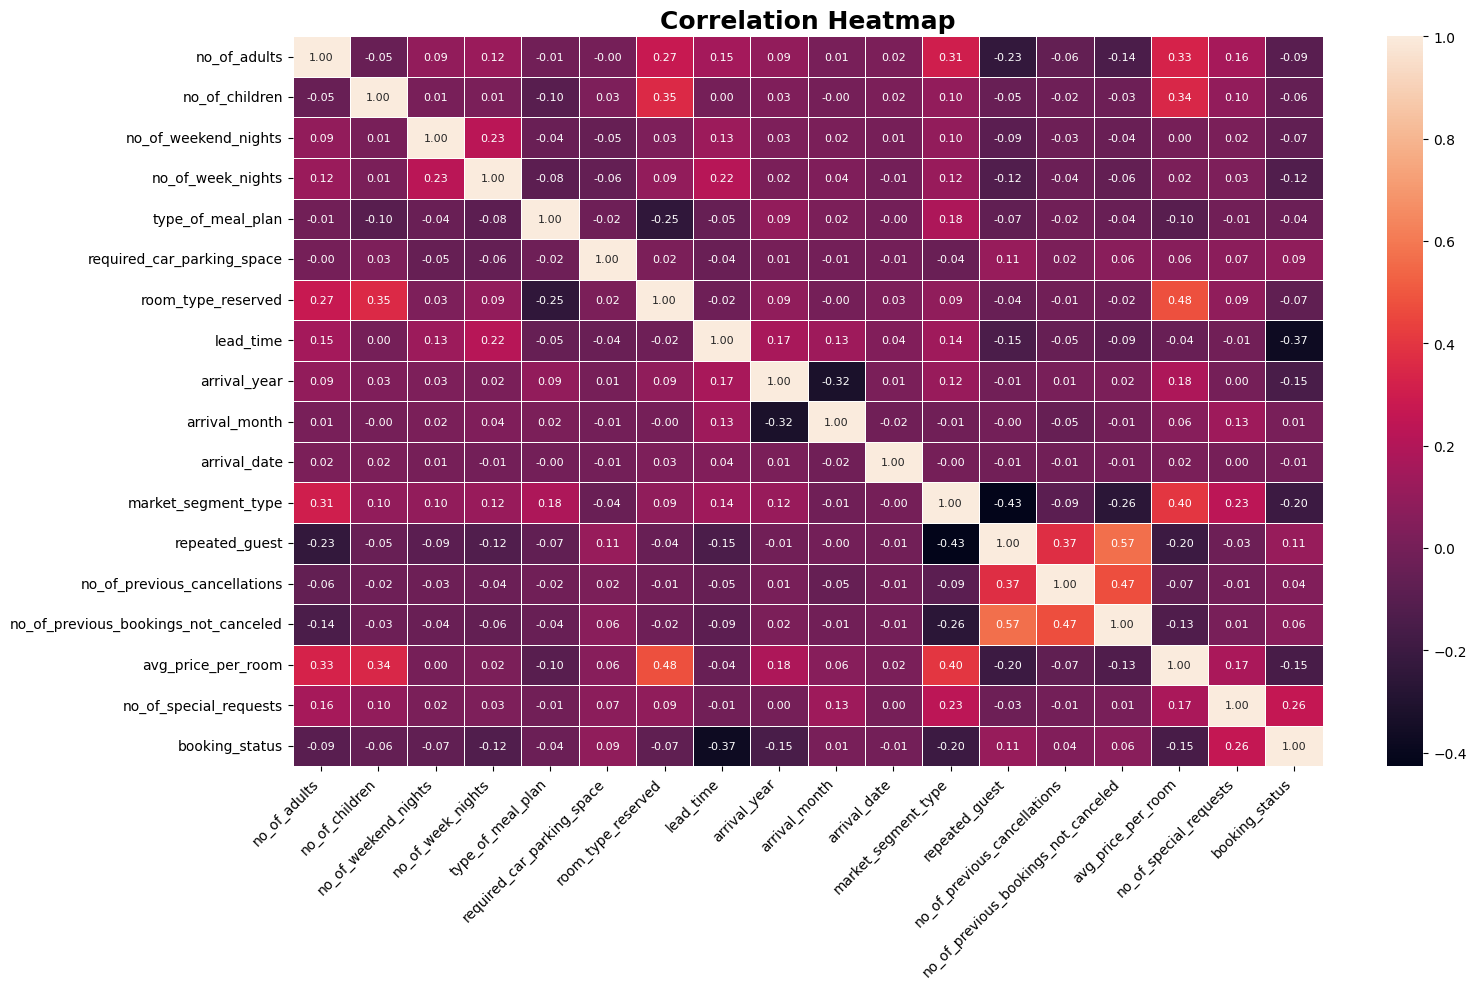

In [35]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(16, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    square=False,
    annot_kws={"size": 8},
)

plt.title("Correlation Heatmap", fontsize=18, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [36]:
skewness = df.skew()
skewness

no_of_adults                            -0.287416
no_of_children                           4.010382
no_of_weekend_nights                     0.658506
no_of_week_nights                        1.591273
type_of_meal_plan                        1.659993
required_car_parking_space               4.685861
room_type_reserved                       1.378664
lead_time                                1.408960
arrival_year                            -1.953723
arrival_month                           -0.292567
arrival_date                             0.011949
market_segment_type                     -2.341217
repeated_guest                           5.324586
no_of_previous_cancellations            22.950242
no_of_previous_bookings_not_canceled    16.807723
avg_price_per_room                       0.583667
no_of_special_requests                   0.923669
booking_status                          -0.933269
dtype: float64

In [37]:
for col in df.columns.to_list():
    if df[col].skew() > 5:
        df[col] = np.log1p(df[col])

In [38]:
df.skew()

no_of_adults                            -0.287416
no_of_children                           4.010382
no_of_weekend_nights                     0.658506
no_of_week_nights                        1.591273
type_of_meal_plan                        1.659993
required_car_parking_space               4.685861
room_type_reserved                       1.378664
lead_time                                1.408960
arrival_year                            -1.953723
arrival_month                           -0.292567
arrival_date                             0.011949
market_segment_type                     -2.341217
repeated_guest                           5.324586
no_of_previous_cancellations            13.595670
no_of_previous_bookings_not_canceled     7.602069
avg_price_per_room                       0.583667
no_of_special_requests                   0.923669
booking_status                          -0.933269
dtype: float64

### **Imbalanced Data Handling**

In [39]:
df["booking_status"].value_counts()

booking_status
1    15171
0     6154
Name: count, dtype: int64

In [40]:
X = df.drop(columns=["booking_status"], axis=1)
Y = df["booking_status"]

In [41]:
X.columns

Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space',
       'room_type_reserved', 'lead_time', 'arrival_year', 'arrival_month',
       'arrival_date', 'market_segment_type', 'repeated_guest',
       'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled',
       'avg_price_per_room', 'no_of_special_requests'],
      dtype='object')

In [42]:
Y

0        1
1        0
2        1
3        1
4        1
        ..
29015    1
29016    0
29017    1
29018    0
29019    1
Name: booking_status, Length: 21325, dtype: int64

In [43]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, Y_resampled = smote.fit_resample(X=X, y=Y)

Y_resampled.value_counts()

booking_status
1    15171
0    15171
Name: count, dtype: int64

In [44]:
for col in X.columns.to_list():
    print(X[col].value_counts())
    print("============================================")
    print("\n\n")

no_of_adults
2    15440
1     3994
3     1773
0      105
4       13
Name: count, dtype: int64



no_of_children
0     19270
1      1219
2       817
3        17
10        1
9         1
Name: count, dtype: int64



no_of_weekend_nights
0    9080
1    6089
2    5916
4     105
3      99
5      19
6      16
7       1
Name: count, dtype: int64



no_of_week_nights
2     5902
1     5793
3     4632
4     1962
0     1518
5     1143
6      141
7       79
8       48
10      39
9       25
11      15
12       8
14       7
15       6
17       3
13       3
16       1
Name: count, dtype: int64



type_of_meal_plan
0    16759
3     3600
1      962
2        4
Name: count, dtype: int64



required_car_parking_space
0    20469
1      856
Name: count, dtype: int64



room_type_reserved
0    15334
3     4438
5      750
1      489
4      193
6      117
2        4
Name: count, dtype: int64



lead_time
0      928
1      721
2      475
3      458
4      449
      ... 
318      1
300      1
381      1
328      

In [45]:
df.shape

(21325, 18)

In [46]:
df_resampled_balanced = pd.DataFrame(X_resampled, columns=X_resampled.columns)
df_resampled_balanced["booking_status"] = Y_resampled
df_resampled_balanced.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,2,1,0,0,3,68,2018,3,19,4,0.0,0.0,0.0,105.30,2,1
1,2,2,2,5,0,0,5,196,2018,7,24,4,0.0,0.0,0.0,158.95,0,0
2,2,0,1,3,3,0,0,52,2018,12,1,4,0.0,0.0,0.0,74.80,2,1
3,2,0,2,0,0,0,3,3,2018,2,21,4,0.0,0.0,0.0,105.00,0,1
4,2,0,1,4,0,0,3,62,2018,4,11,4,0.0,0.0,0.0,112.20,0,1


In [47]:
df_resampled_balanced.shape

(30342, 18)

In [48]:
df = df_resampled_balanced.copy()

In [49]:
df.shape

(30342, 18)

### **Feature Selection**

In [50]:
len(df.columns)

18

In [51]:
from sklearn.ensemble import RandomForestClassifier

In [52]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,2,1,0,0,3,68,2018,3,19,4,0.0,0.0,0.0,105.30,2,1
1,2,2,2,5,0,0,5,196,2018,7,24,4,0.0,0.0,0.0,158.95,0,0
2,2,0,1,3,3,0,0,52,2018,12,1,4,0.0,0.0,0.0,74.80,2,1
3,2,0,2,0,0,0,3,3,2018,2,21,4,0.0,0.0,0.0,105.00,0,1
4,2,0,1,4,0,0,3,62,2018,4,11,4,0.0,0.0,0.0,112.20,0,1


In [53]:
X = df.drop(columns=["booking_status"], axis=1)
Y = df["booking_status"]

In [54]:
model = RandomForestClassifier(random_state=42)

model.fit(X, Y)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
feature_importance = model.feature_importances_

In [57]:
feature_importance_df = pd.DataFrame(
    {"feature": X.columns, "importance": feature_importance}
)

In [58]:
feature_importance_df

,feature,importance
0,no_of_adults,0.017710
1,no_of_children,0.006679
2,no_of_weekend_nights,0.030570
3,no_of_week_nights,0.045595
4,type_of_meal_plan,0.020824
5,required_car_parking_space,0.011269
6,room_type_reserved,0.019666
7,lead_time,0.263678
8,arrival_year,0.016479
9,arrival_month,0.086184


In [61]:
sorted_df_by_importance = feature_importance_df.sort_values(
    by="importance", ascending=False
)

In [65]:
top_10_features = list(sorted_df_by_importance["feature"].head(10).values)
top_10_features

['lead_time',
 'no_of_special_requests',
 'avg_price_per_room',
 'arrival_month',
 'arrival_date',
 'market_segment_type',
 'no_of_week_nights',
 'no_of_weekend_nights',
 'type_of_meal_plan',
 'room_type_reserved']

In [67]:
top_10_df = df[top_10_features + ["booking_status"]]

In [71]:
top_10_df.head()

,lead_time,no_of_special_requests,avg_price_per_room,arrival_month,arrival_date,market_segment_type,no_of_week_nights,no_of_weekend_nights,type_of_meal_plan,room_type_reserved,booking_status
0,68,2,105.30,3,19,4,1,2,0,3,1
1,196,0,158.95,7,24,4,5,2,0,5,0
2,52,2,74.80,12,1,4,3,1,3,0,1
3,3,0,105.00,2,21,4,0,2,0,3,1
4,62,0,112.20,4,11,4,4,1,0,3,1


In [70]:
len(top_10_df.columns)

11

In [72]:
df = top_10_df.copy()

### **Model Selection**

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [74]:
X = df.drop(columns=["booking_status"], axis=1)
Y = df["booking_status"]

In [75]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, shuffle=True, random_state=42
)

In [76]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Logistic Regression": LogisticRegression(),
    "Naive Bayes": GaussianNB(),
    "K-Neighbors": KNeighborsClassifier(n_neighbors=10),
    "SVC": SVC(),
    "Decision Tree": DecisionTreeClassifier(),
    "AdaBoost Classifier": AdaBoostClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGB Classifier": XGBClassifier(),
    "Light GBM": LGBMClassifier(),
}

In [87]:
def calculate_metrics(train_actual, train_pred, test_actual, test_pred):
    return {
        "train": {
            "accuracy": accuracy_score(train_actual, train_pred),
            "recall": recall_score(train_actual, train_pred),
            "precision": precision_score(train_actual, train_pred),
            "f1_score": f1_score(train_actual, train_pred),
        },
        "test": {
            "accuracy": accuracy_score(test_actual, test_pred),
            "recall": recall_score(test_actual, test_pred),
            "precision": precision_score(test_actual, test_pred),
            "f1_score": f1_score(test_actual, test_pred),
        },
    }

In [88]:
metrics = {}

for model_name, model in classifiers.items():
    model.fit(X_train, Y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    metrics[model_name] = calculate_metrics(Y_train, train_pred, Y_test, test_pred)

In [89]:
metrics

{'Random Forest': {'train': {'accuracy': 0.9967041568821324,
   'recall': 0.9966917541973369,
   'precision': 0.9966917541973369,
   'f1_score': 0.9966917541973369},
  'test': {'accuracy': 0.8854836052067886,
   'recall': 0.8857142857142857,
   'precision': 0.8883099967437317,
   'f1_score': 0.8870102422370346}},
 'Logistic Regression': {'train': {'accuracy': 0.7746055287768302,
   'recall': 0.7336862128856174,
   'precision': 0.7976083438230535,
   'f1_score': 0.7643131004178693},
  'test': {'accuracy': 0.7678365463832592,
   'recall': 0.7269480519480519,
   'precision': 0.7976487353045957,
   'f1_score': 0.7606590793273315}},
 'Naive Bayes': {'train': {'accuracy': 0.7711860915420427,
   'recall': 0.7286411380365562,
   'precision': 0.794911125146621,
   'f1_score': 0.7603348580305515},
  'test': {'accuracy': 0.769978579667161,
   'recall': 0.727922077922078,
   'precision': 0.8007142857142857,
   'f1_score': 0.7625850340136054}},
 'K-Neighbors': {'train': {'accuracy': 0.7934330325876

In [90]:
from IPython.display import display

metrics_df = pd.DataFrame(
    {
        model_name: {
            f"{dataset}_{metric}": value
            for dataset, scores in model_results.items()
            for metric, value in scores.items()
        }
        for model_name, model_results in metrics.items()
    }
).T
metrics_df.index_name = "Model"

display(metrics_df)

,train_accuracy,train_recall,train_precision,train_f1_score,test_accuracy,test_recall,test_precision,test_f1_score
Random Forest,0.996704,0.996692,0.996692,0.996692,0.885484,0.885714,0.888310,0.887010
Logistic Regression,0.774606,0.733686,0.797608,0.764313,0.767837,0.726948,0.797649,0.760659
Naive Bayes,0.771186,0.728641,0.794911,0.760335,0.769979,0.727922,0.800714,0.762585
K-Neighbors,0.793433,0.667687,0.890175,0.763043,0.750041,0.619805,0.846563,0.715651
SVC,0.727846,0.705980,0.736688,0.721007,0.732411,0.712013,0.748464,0.729784
Decision Tree,0.996704,0.993466,0.999917,0.996681,0.837700,0.825649,0.850217,0.837753
AdaBoost Classifier,0.801879,0.786784,0.810031,0.798238,0.798319,0.787987,0.809540,0.798618
Gradient Boosting,0.836403,0.856009,0.822734,0.839042,0.832592,0.856494,0.821295,0.838525
XGB Classifier,0.912042,0.914399,0.909510,0.911948,0.867853,0.876299,0.865064,0.870645
Light GBM,0.879661,0.890828,0.870595,0.880595,0.864722,0.881494,0.856197,0.868661


### **Training the Random Forest Model and HyperParameter Tuning**

In [91]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [92]:
rf = RandomForestClassifier()

params = {
    "n_estimators": randint(100, 500),
    "max_depth": randint(10, 50),
    "min_samples_split": randint(2, 10),
    "min_samples_leaf": randint(1, 5),
    "bootstrap": [True, False],
}

In [93]:
randomized_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=params,
    n_iter=10,
    cv=5,
    verbose=1,
    scoring="accuracy",
    n_jobs=-1,
)

In [94]:
randomized_search.fit(X_train, Y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,estimator,RandomForestClassifier()
,param_distributions,"{'bootstrap': [True, False], 'max_depth': <scipy.stats....0027814B559F0>, 'min_samples_leaf': <scipy.stats....0027814C09F00>, 'min_samples_split': <scipy.stats....0027814B56AA0>, ...}"
,n_iter,10
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [95]:
randomized_search.best_score_

np.float64(0.8790017809427667)

In [96]:
randomized_search.best_params_

{'bootstrap': False,
 'max_depth': 39,
 'min_samples_leaf': 2,
 'min_samples_split': 4,
 'n_estimators': 189}

In [98]:
best_estimator = randomized_search.best_estimator_

In [99]:
y_pred = best_estimator.predict(X_test)

In [100]:
accuracy_score(Y_test, y_pred)

0.8836711155050255

In [101]:
import joblib

joblib.dump(best_estimator, "best_random_forest.pkl")

['best_random_forest.pkl']

In [102]:
X.head()

,lead_time,no_of_special_requests,avg_price_per_room,arrival_month,arrival_date,market_segment_type,no_of_week_nights,no_of_weekend_nights,type_of_meal_plan,room_type_reserved
0,68,2,105.30,3,19,4,1,2,0,3
1,196,0,158.95,7,24,4,5,2,0,5
2,52,2,74.80,12,1,4,3,1,3,0
3,3,0,105.00,2,21,4,0,2,0,3
4,62,0,112.20,4,11,4,4,1,0,3


In [103]:
model = joblib.load("best_random_forest.pkl")

answer = model.predict([[68, 2, 105.30, 3, 19, 4, 1, 2, 0, 3]])
print()

array([1])

In [104]:
le.inverse_transform(answer)

array(['Not_Canceled'], dtype=object)